# PNM Generation and Mercury Intrusion Simulation




This notebook demonstrates how to generate a random pore network model (PNM)
from experimental mercury intrusion porosimetry (MIP) data, compare the generated
network against the experimental distributions, run a mercury intrusion simulation,
and visualize the resulting 3D network.

**Key concept:** The experimental MIP data provides the **throat (capillary)**
size distribution. From this distribution, we predict the corresponding **pore**
size distribution such that, when pores are connected by throats, the measured
throat distribution is recovered.

**Workflow:**
1. Read all experimental source files (CSV) and plot their intrusion curves
2. Select one file and prepare the experimental throat distribution
3. Predict the pore distribution from the throat distribution (corrective factor `e`, PRTRR)
4. Define model parameters (number of pores, surface coverage ratio, etc.)
5. Generate a pore network using the predicted pore distribution
6. Compare experimental vs generated throat/pore distributions
7. Mercury intrusion simulation: compare experimental vs simulated curves
8. 3D visualization and image saving

Generated networks are saved in `examples/networks/`.



## 1. Imports and Configuration



In [1]:
# Add project root to Python path so the 'pnm' package can be imported
import sys
from pathlib import Path
sys.path.insert(0, "/home/jlux/Nextcloud/Codes/python3/pnm")

import os
import numpy as np
import matplotlib.pyplot as plt
from functools import partial
from datetime import datetime

# Plotting inline
%matplotlib inline

# PNM package
import pnm
from pnm import pore_network
from pnm.Generators import random_PNM
from pnm.Algorithms.percolation import mercury_intrusion
from pnm.Stats import stats, distribution, inverse_transform_sampling_from_raw_data, invert_pore_distribution_kernel, save_distributions, jensen_shannon_divergence
from pnm.mip import load_mip_data, MIPData

# Project paths
PROJECT_ROOT = Path("/home/jlux/Nextcloud/Codes/python3/pnm")
DATA_DIR = PROJECT_ROOT / "examples" / "data"
NETWORKS_DIR = PROJECT_ROOT / "examples" / "networks"
NETWORKS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Networks directory: {NETWORKS_DIR}")

Project root: /home/jlux/Nextcloud/Codes/python3/pnm
Data directory: /home/jlux/Nextcloud/Codes/python3/pnm/examples/data
Networks directory: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks


## 2. Read All Source Files




The `examples/data/` directory contains CSV files with mercury intrusion porosimetry
data. Each file has two columns: pore **diameter** and cumulative intruded **volume**.

All experimental intrusion curves are plotted below so you can choose which file
to use for network generation. Modify `selected_file_index` in the next cell.



In [2]:
csv_files = sorted([f for f in os.listdir(DATA_DIR) if f.endswith(".csv")])
print(f"Found {len(csv_files)} CSV file(s) in {DATA_DIR}:")
for i, f in enumerate(csv_files):
    print(f"  [{i}] {f}")


Found 5 CSV file(s) in /home/jlux/Nextcloud/Codes/python3/pnm/examples/data:
  [0] GM1.csv
  [1] GM2.csv
  [2] MP.csv
  [3] PCI.csv
  [4] PCV.csv


### Plot all experimental intrusion curves



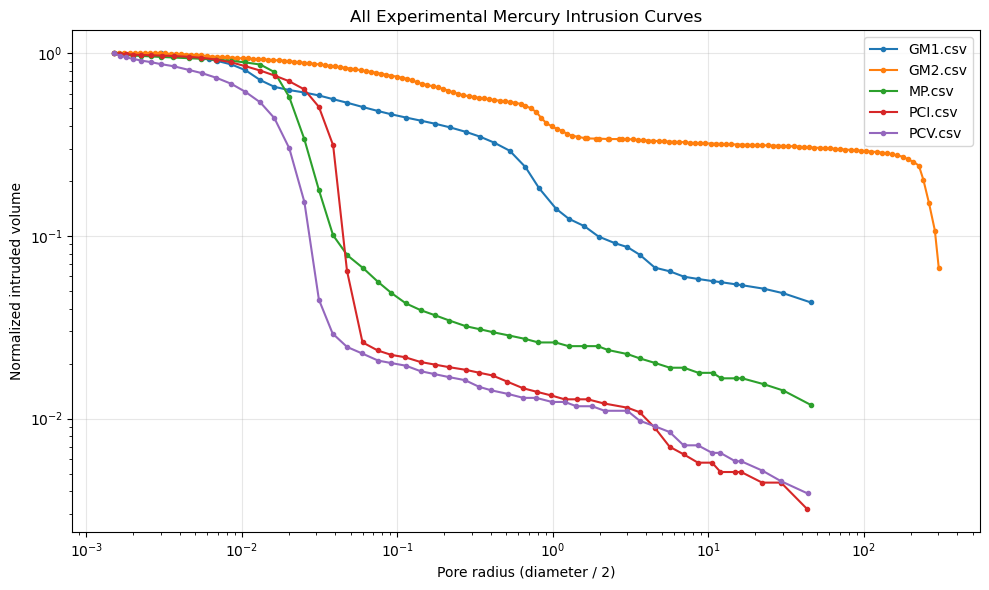

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

all_data = {}
for i, fname in enumerate(csv_files):
    filepath = DATA_DIR / fname
    # load_mip_data also returns the raw unfiltered curves (diameters + cumulative volume).
    mip = load_mip_data(filepath)
    diam = mip.diameters          # sorted ascending
    vol = mip.volumes_cum         # cumulative intruded volume at each diameter
    keep = vol > 1e-6                # drop zero-volume points (not representable on a log scale)
    cum_vol = vol[keep] / vol.max() if vol.max() > 0 else vol[keep]
    ax.plot(diam[keep] / 2.0, cum_vol, 'o-', label=fname, markersize=3)
    all_data[fname] = (diam, vol)

ax.set_xlabel('Pore radius (diameter / 2)')
ax.set_ylabel('Normalized intruded volume')
ax.set_title('All Experimental Mercury Intrusion Curves')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

plt.tight_layout()
plt.show()

### Select the file and target window

The next cell selects **which experimental file** to use (`selected_file_index`) and applies the
**target window**: the asymmetric cumulative-volume cut `low_frac`/`high_frac` — keep throats whose
cumulative intruded volume lies in [50 %, 95 %] (the asym50_95 study window → [0.068, 26.53] µm on GM1).

The whole pipeline below is set to the **validated asym50_95 recipe** (GM1, seed 7; full study
history in `AGENTS.md` and `doc/experiment-summary.typ`, rows 21–23):

| Step | Parameter values |
|------|------------------|
| Window | cumulative volume [50 %, 95 %] → throat radius [0.068, 26.53] µm (large band ≥0.5 µm = 53.2 % of target) |
| Inversion | exclusion kernel `e=1.75`, `sratio=0.7` (section 3) |
| Throat method | v1 two-phase `surf`: `order="decreasing"`, `phase1_z=0` (no dedicated large-pair pass), `p2f=2`, `maxc=1024` (section 4) |

Result: **JSD 0.0093** at N=150k (study, row 22); JSD 0.0118 / large band 47.4 % vs exp 53.2 % in the
N=250k network generated 2026-11-20 (`examples/networks/20261120_asym5095_250k_kernel_*`).
Other validated recipes (W1, keep75) are documented in `AGENTS.md` / `doc/experiment-summary.typ`.

In [4]:
# ============================================================
# USER PARAMETERS - select which file to use + target window (asym50_95 recipe)
# ============================================================
selected_file_index = 0  # change this to use a different file


selected_file = csv_files[selected_file_index]
filepath = DATA_DIR / selected_file
print(f"Selected file: {filepath}")

# ------------------------------------------------------------------
# Target window (asym50_95 recipe): keep throats whose cumulative intruded volume lies in
# [low_frac, high_frac]. On GM1 this is the study window [0.068, 26.53] um (large band >= 0.5 um =
# 53.2 % of the target). The full extent of the selected curve is shown BEFORE any window is
# applied, so the chosen
# window can be inspected against real values of this file. The radii of the distribution
# are the BIN CENTERS (midradii): each bin is one throat size class characterized by its
# center radius. F(r) = cumulative intruded volume fraction: share of the total intruded
# volume in throats with radius <= r (same curve as section 7).
# ------------------------------------------------------------------
mip_full = load_mip_data(filepath, cumulative_proba=1.0)   # no filter at all: every bin is kept
midradii_all = mip_full.midradii          # bin centers (um), ascending
F = np.cumsum(mip_full.volumes)           # F(mid_i) = fraction of intruded volume in bins up to i

# Truncate the distribution to avoid too large Rmax/Rmin ratio
high_frac = 0.95   # upper cumulative-volume cutoff: drops throats above this fraction of intruded volume
low_frac = 0.5 # lower cumulative-volume cutoff: drops the smallest throats below this fraction
i_min = int(np.searchsorted(F, low_frac))                    # first bin with F >= low_frac (F is ascending)
i_max = min(int(np.searchsorted(F, high_frac)), len(F) - 1)  # first bin with F >= high_frac (clamped for high_frac=1.0)
minr = midradii_all[i_min]   # lower window bound (throat radius, um)
maxr = midradii_all[i_max]   # upper window bound (throat radius, um)

n_ref = 9   # number of reference points (log-spaced radii between the two extremes)
r_ref = np.geomspace(midradii_all.min(), midradii_all.max(), n_ref)
ref_idx = np.unique(np.searchsorted(midradii_all, r_ref))
print(f"Full curve extent: r from {midradii_all.min():.4f} to {midradii_all.max():.2f} um ({len(midradii_all)} bins)")
print(f"Rmax/Rmin = {midradii_all.max()/midradii_all.min():.2f}")
print("Reference points (bin center -> F(r) = % of intruded volume in throats <= r):")
for i in ref_idx:
    print(f"  r = {midradii_all[i]:10.4f} um   F(r) = {100*F[i]:6.2f}%")

print(f"Keep pore from {low_frac*100}% to {high_frac*100}%")
print(f"Min radius {minr:4.2e}, Max radius {maxr:4.2e}")
mip = load_mip_data(filepath, rmin=minr, rmax=maxr)
print(f"Ratio Rmax/Rmin : {mip.midradii.max()/mip.midradii.min()}")

Selected file: /home/jlux/Nextcloud/Codes/python3/pnm/examples/data/GM1.csv
Full curve extent: r from 0.0033 to 111.67 um (46 bins)
Rmax/Rmin = 33534.10
Reference points (bin center -> F(r) = % of intruded volume in throats <= r):
  r =     0.0033 um   F(r) =   1.86%
  r =     0.0147 um   F(r) =  34.61%
  r =     0.0541 um   F(r) =  49.38%
  r =     0.1962 um   F(r) =  60.72%
  r =     0.7411 um   F(r) =  81.75%
  r =     2.7643 um   F(r) =  91.32%
  r =     9.6550 um   F(r) =  94.35%
  r =    38.0106 um   F(r) =  95.68%
  r =   111.6685 um   F(r) = 100.00%
Keep pore from 50.0% to 95.0%
Min radius 6.80e-02, Max radius 2.65e+01
Ratio Rmax/Rmin : 390.31978668628165


## 3. Prepare Experimental Data



The experimental CSV gives the **cumulative intruded volume** vs diameter.
`pnm.mip.load_mip_data` reads it and derives, in one call:

1. **Throat (capillary) distribution** `volumes`: the volume intruded in each
   diameter class, computed as `-np.diff(volumes_cum)` (negative difference
   because diameters are sorted ascending while cumulative volume decreases
   when read from large to small pores), normalized over the kept bins.

2. **Pore distribution** `pdist` (next section): predicted from the throat
   distribution with the **exclusion-kernel inversion**
   (`pnm.Stats.invert_pore_distribution_kernel`). It iteratively computes the pore
   distribution such that, when pores are connected by throats *the way the generator
   actually pairs them* (a large pore spends its surface budget on nearby small throats
   first), the measured throat distribution is recovered.

The model uses:
- **`e`**: empirical corrective factor (e=1 means no correction)
- **`PRTRR`**: pore radius to throat radius ratio (typically 2)
- **`target_porosity`** and **`sratio`**: the generation porosity and surface coverage
  ratio. The kernel derives each class's connection reach from its surface budget, so the
  predicted pore distribution depends on them; they must match the values passed to
  `random_PNM` in section 5 (defined together with `e`/`PRTRR` in the next cell).

Full derivation: `doc/pore-distribution-inversion.md`.

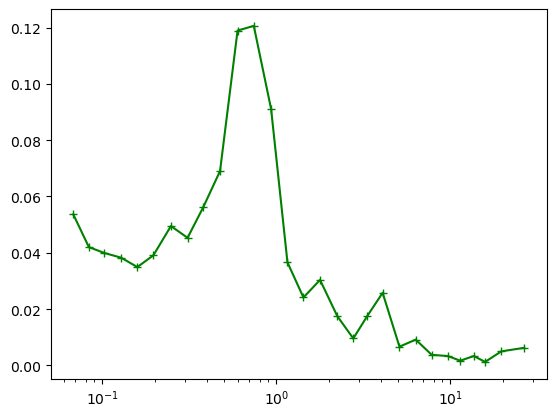

Number of throat radius bins: 29
Throat radius (µm) min - max: 0.0604 - 30.3377
Ratio Rmax/Rmin:  5.02e+02
Lost volume fraction ('porosité perdue'): 54.23%


In [5]:
# Unpack the experimental data (bin edges, per-bin volumes and raw curves).
throat_radii = mip.throat_radii   # bin EDGES: n_bins + 1 values; bin i spans [t[i], t[i+1]]
volumes = mip.volumes             # normalized intruded volume per kept bin
deltaR = mip.deltaR               # bin widths
midradii = mip.midradii           # bin centers
diameters = mip.diameters         # raw diameters (µm), unfiltered - used in section 7
volumes_cum = mip.volumes_cum     # raw cumulative intruded volume, unfiltered - used in section 7

rmin = throat_radii.min()
rmax = throat_radii.max()

plt.plot(midradii, volumes, '+-', c='green', label='Exp. distribution')
plt.xscale("log")
plt.show()

print(f"Number of throat radius bins: {len(volumes)}")
print(f"Throat radius (µm) min - max: {rmin:.4f} - {rmax:.4f}")
print(f"Ratio Rmax/Rmin: {rmax / rmin : 4.2e}")
print(f"Lost volume fraction ('porosité perdue'): {100*mip.lost_volume_frac:.2f}%")

### Predict pore distribution from throat distribution



pdist min: 0.000000
pdist max: 0.357349, sum: 1.000000


/home/jlux/Nextcloud/Codes/python3/pnm/pnm/Stats.py:753: UserWarning: invert_pore_distribution_kernel: fixed point not reached within 500 iterations (forward-model residual 1.845e-03 > 1e-3); returning the last iterate.
  warn(


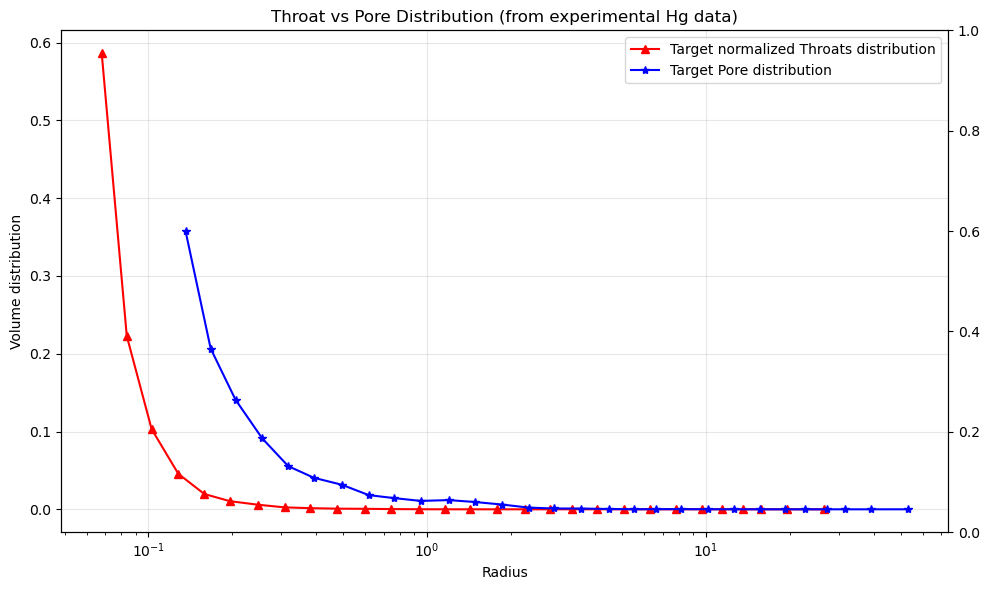

In [6]:
# ============================================================
# USER PARAMETERS - modify these values as needed
# The exclusion-kernel inversion couples the pore prediction to the GENERATION parameters, so
# target_porosity and sratio are defined HERE (shared with section 4/5 network generation).
# They must match the porosity/sratio passed to random_PNM in "Generate Pore Network".
# Values below = validated asym50_95 recipe (GM1, seed 7; study row 22 of doc/experiment-summary.typ); override freely.
# ============================================================
e = 1.75                          # empirical corrective factor (kernel model; tuned on the asym50_95 GM1 study)
sratio = 0.7                      # max pore surface covered by throats (shared with network generation, section 4/5)

PRTRR = 2.0                      # pore radius to throat radius ratio
target_porosity = 0.35           # target pore-body porosity (shared with network generation, section 4/5)
# ============================================================

# cdist + pdist: predicted pore distribution from the experimental throat distribution.
# Uses the EXCLUSION-KERNEL inversion (pnm.Stats.invert_pore_distribution_kernel): it models the
# spatial pairing actually performed by the generator (a large pore spends its surface budget on
# nearby small throats first), so unlike the independent model it also depends on the generation
# sratio and porosity. See doc/pore-distribution-inversion.md for the full derivation.
cdist, pdist = invert_pore_distribution_kernel(
    volumes, midradii, deltaR, e=e, PRTRR=PRTRR, porosity=target_porosity, sratio=sratio
)
cumcdist = np.cumsum(cdist)

print(f"pdist min: {pdist.min():.6f}")
print(f"pdist max: {pdist.max():.6f}, sum: {pdist.sum():.6f}")

# Visualize: throat distribution vs experimental vs predicted pore distribution
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()

ax1.plot(midradii, cdist, '^-', c='red', label='Target normalized Throats distribution')
# ax1.plot(midradii, volumes, '+-', c='green', label='Exp. distribution')
ax1.plot(midradii * PRTRR, pdist, "*-", c="blue", label="Target Pore distribution")

ax1.set_xlabel('Radius')
ax1.set_ylabel('Volume distribution')
ax1.set_title('Throat vs Pore Distribution (from experimental Hg data)')
ax1.set_xscale('log')
ax1.legend()
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Pore radius bins for network generation



In [7]:
# Pore radius bins = throat radii * PRTRR
pore_radii_bins = throat_radii * PRTRR
pore_deltaR = deltaR * PRTRR
pore_midradii = midradii * PRTRR
print(f"Pore radius range: {pore_radii_bins[0]:.4f} - {pore_radii_bins[-1]:.4f}")


Pore radius range: 0.1209 - 60.6755


## 4. Model Parameters



Parameters below are easily modifiable. Change the values and re-run the cells to explore different
network configurations. The values shown are the **validated asym50_95 recipe** (GM1, seed 7; study
row 22 of `doc/experiment-summary.typ`). Note: `e`, `PRTRR`, `target_porosity` and `sratio` are defined in
section 3 because the exclusion-kernel inversion depends on them; they are shared with this step.

- **`npores`**: target number of pores (validated at N=150k in the study, N=250k network generated 2026-11-20)
- **`minc` / `maxc`**: minimum / maximum pore connectivity (`maxc` is the two-phase zmax; 1024 in the study). `minc` is only forwarded to periodic throats (unused by `"surf"`).
- **`throat_method`**: `"surf"` = two-phase add_throats_by_surf — phase 1 (optional, `phase1_z > 0`) seeds each pore with its LARGEST partners; phase 2 fills the remaining surface budget nearest-surface-distance-first over a `p2f*r_i + R_max` ball, then enforces the `phase2_zmin` connectivity floor.
- **`order`**: phase-2 processing order by radius — `"decreasing"` is best for this recipe (large pores claim partners first while all budgets are fresh).
- **`phase1_z`**: number of LARGEST-radius neighbors connected per pore in phase 1; `0` disables the dedicated large-pair pass (best on this window at every e/sr).

Other validated recipes (W1, keep75) and their parameters: see `AGENTS.md` / `doc/experiment-summary.typ`.

In [8]:
# ============================================================
# USER PARAMETERS - modify these values as needed
# NOTE: e, PRTRR, target_porosity and sratio are defined in section 3 (cell "Predict pore
# distribution") because the kernel inversion depends on them; they are shared with this step.
# Values below = validated asym50_95 recipe (GM1, seed 7; study row 22 of doc/experiment-summary.typ).
# See AGENTS.md / doc/experiment-summary.typ for the other validated recipes (W1, keep75).
# ============================================================
npores = 250000                   # target number of pores (validated at N=1.5e5 in the study, N=2.5e5 network generated 2026-11-20; lower for a quick run)
minc = 2                           # minimum pore connectivity (= v3 pass-1 per-large-pore floor)
maxc = 1024                         # maximum pore connectivity (two-phase zmax; 1024 used by the asym50_95 study)
seed = 7                           # shared seed for reproducibility (None = unseeded)
BCgridsize = 150                   # grid resolution for boundary detection


throat_method = "surf"         # two-phase add_throats_by_surf: phase 1 seeds largest partners, phase 2 fills by surface distance

# Phase 1 (optional): seed each pore with its LARGEST partners; runs only when phase1_z > 0.
order = "decreasing"           # phase-2 processing order by radius; "decreasing" is best for this recipe (giants claim partners first while budgets are fresh)
phase1_radius_factor = 2       # phase-1 candidate ball radius = (factor + 1) * r_i
phase1_min_neighbors = 32      # min candidates in the phase-1 ball (widens to this many if sparse)
phase1_z = 0                   # number of LARGEST-radius neighbors connected per pore in phase 1 (0 disables the dedicated large-pair pass — best on this window)

# Phase 2: fill remaining budget with nearest-by-surface-distance neighbors + connectivity floor.
phase2_radius_factor = 2       # phase-2 candidate ball radius = factor * r_i + R_max (R_max = largest pore)
phase2_min_neighbors = 32      # min candidates in the phase-2 ball (widens to this many if sparse)
phase2_zmin = 2                # connectivity floor: force-connect nearest neighbors below this count

min_neighbors_factor = 10      # ignored by the new "surf"; still forwarded to random_PNM (periodic throats / other methods)

# throat_method = "surf_v3"      # two-pass: independent large-pore sub-network + budget-driven pass 2
# sort_by_radius = False         # ignored by surf_v3 (kept so the call below is uniform)
# minc_search_factor = None      # ignored by surf_v3
# search_radius_factor = 2.0     # ignored by surf_v3
# large_radius_cutoff = 0.5      # v3 pass-1 threshold (um, PORE radius): interconnect pores >= this
# min_neighbors_factor = 2       # param_study default used by all keep75 studies; surf_v3 ignores it — only affects periodic throats

# ============================================================

print("Model parameters:")
print(f"  npores = {npores}")
print(f"  e = {e}, PRTRR = {PRTRR}   (defined in section 3)")
print(f"  target_porosity = {target_porosity}, sratio = {sratio}   (defined in section 3)")
print(f"  minc = {minc}, maxc = {maxc}, min_neighbors_factor = {min_neighbors_factor}")
print(f"  throat_method = {throat_method}   (two-phase add_throats_by_surf; maxc -> zmax)")
if throat_method == "surf":
    print(f"  order = {order}; phase1 (z={phase1_z}, factor={phase1_radius_factor}, min_nb={phase1_min_neighbors})")
    print(f"  phase2 (factor={phase2_radius_factor}, min_nb={phase2_min_neighbors}, zmin={phase2_zmin})")
print(f"  seed = {seed}")

Model parameters:
  npores = 250000
  e = 1.75, PRTRR = 2.0   (defined in section 3)
  target_porosity = 0.35, sratio = 0.7   (defined in section 3)
  minc = 2, maxc = 1024, min_neighbors_factor = 10
  throat_method = surf   (two-phase add_throats_by_surf; maxc -> zmax)
  order = decreasing; phase1 (z=0, factor=2, min_nb=32)
  phase2 (factor=2, min_nb=32, zmin=2)
  seed = 7


## 5. Generate Pore Network




We generate a random packing of pores using the **predicted pore distribution**
`pdist` (derived from the experimental throat distribution). The pore radius
bins are `throat_radii * PRTRR`.

The packing uses the fast **kdtree** algorithm (`packing_method="kdtree"`, default)
which is suitable for networks with tens to hundreds of thousands of pores.



In [9]:
# Build radius distribution from the predicted pore distribution.
# pdist is a COUNT distribution (one probability per bin, summing to 1). The sampler takes the
# FULL bin edges (n_bins + 1 values) and spreads each bin's mass uniformly over its own span
# [bins[i], bins[i+1]] - passing only the left edges would shift every bin one size down and
# clip part of the smallest bin to zero.
# The kernel inversion has NO continuous size-shift gauge (unlike the independent model), so the
# predicted pore distribution is sampled directly with no additional shift.
rdist_data, rdist_bins = pdist, pore_radii_bins

rdist = partial(
    inverse_transform_sampling_from_raw_data,
    rdist_data,
    bins=rdist_bins,
    high=np.inf
)

print("Radius distribution: predicted pore count distribution from experimental throat data")
print(f"  Pore bins (as fed to sampler): {len(rdist_bins) - 1} bins from {rdist_bins[0]:.4f} to {rdist_bins[-1]:.4f}")

# Generate the network
print("Generating pore network...")
pn = random_PNM(
    npores=npores,
    extent=(1.0, 1.0, 1.0),
    porosity=target_porosity,
    rdist=rdist,
    sratio=sratio,
    PRTRR=PRTRR,
    minc=minc,                    # minimum connectivity; only used by periodic throats here (two-phase "surf" ignores it)
    maxc=maxc,                    # maximum pore connectivity (two-phase zmax; see section 4)
    min_neighbors_factor=min_neighbors_factor,  # ignored by two-phase "surf"; forwarded for periodic throats
    BCgridsize=BCgridsize,
    throat_method=throat_method,  # two-phase add_throats_by_surf (asym50_95 recipe; see section 4)
    order=order,                              # phase-2 processing order by radius
    phase1_radius_factor=phase1_radius_factor,# phase-1 candidate ball = (factor + 1) * r_i
    phase1_min_neighbors=phase1_min_neighbors,# min candidates in the phase-1 ball
    phase1_z=phase1_z,                        # LARGEST partners connected per pore in phase 1 (>0 enables it)
    phase2_radius_factor=phase2_radius_factor,# phase-2 candidate ball = factor * r_i + R_max
    phase2_min_neighbors=phase2_min_neighbors,# min candidates in the phase-2 ball
    phase2_zmin=phase2_zmin,                  # connectivity floor (force-connect nearest below this)
    packing_method="kdtree",      # options: "kdtree" (default), "kdtree_importance", "opt"
    packing_verbose=True,
    seed=seed,
)

print(f"\nGenerated network:")
print(f"  Number of pores: {pn.graph.number_of_nodes()}")
print(f"  Number of throats: {pn.graph.number_of_edges()}")
print(f"  Extent: {pn.graph.graph.get('extent')}")
print(f"  Porosity: {pn.graph.graph.get('porosity'):.4f}")

# Compute geometry (autothroats=False: random_PNM already set the throat radii and lengths.
# autothroats=True would erase them and reset every throat radius to min(r1, r2), ignoring PRTRR -
# which inflates the total porosity above 1.)
pn.compute_geometry(autothroats=False)
print(f"  Geometry complete: {pn.geom_complete}")
print(f"Average connectivity: {pn.average_connectivity()}")

Radius distribution: predicted pore count distribution from experimental throat data
  Pore bins (as fed to sampler): 29 bins from 0.1209 to 60.6755
Generating pore network...
Max radius = 5.77e+01 and Min radius = 1.21e-01
Extent =  [237.45732462 237.45732462 237.45732462]
Extent/(2*Rmax) = ['2.06', '2.06', '2.06']
Placed pores | current radius | pools drawn | current porosity | unallocated pores



250000 pores generated


Porosity: 0.34999999999999587
Unallocated volume: 0.00e+00, corresponding void_fraction: 0.00 %


250000 nodes to process


Creating 32722 periodic links between face x- and face x+


Creating 57603 periodic links between face y- and face y+



Generated network:
  Number of pores: 250000
  Number of throats: 2411722
  Extent: [np.float64(237.39686714215256), np.float64(237.39682308256485), np.float64(237.3968490773032)]
  Porosity: 0.4630


  Geometry complete: True
Average connectivity: 19.293776


### Save the generated network



In [10]:
import networkx as nx
def _volume_distribution(pn, element: str, bins: np.ndarray) -> np.ndarray:
    """Normalized volume-weighted radius distribution of one element type binned on ``bins``.

    Replicates the binning convention of ``pnm.Stats.stats(mode="vol")`` without any
    matplotlib dependency: first bin is ``[bins[0], bins[1]]``, all other bins are
    ``(bins[i], bins[i+1]]``, result normalized by the total in-range element volume.

    Parameters
    ----------
    pn : pore_network
        Generated network (elements must have ``radius`` and ``volume`` attributes).
    element : str
        "pores" or "throats".
    bins : np.ndarray
        Bin edges, ascending.

    Returns
    -------
    np.ndarray
        Normalized volume per bin (len = len(bins) - 1).
    """
    if element == "pores":
        radii = np.fromiter(nx.get_node_attributes(pn.graph, "radius").values(), dtype=float)
        vol = np.fromiter(nx.get_node_attributes(pn.graph, "volume").values(), dtype=float)
    elif element == "throats":
        radii = np.fromiter(nx.get_edge_attributes(pn.graph, "radius").values(), dtype=float)
        vol = np.fromiter(nx.get_edge_attributes(pn.graph, "volume").values(), dtype=float)
    else:
        raise ValueError(f"element must be 'pores' or 'throats', got {element!r}")

    idx = np.searchsorted(bins, radii, side="right") - 1
    valid = (radii >= bins[0]) & (radii <= bins[-1])
    idx = np.clip(idx, 0, len(bins) - 2)

    data = np.zeros(len(bins) - 1)
    np.add.at(data, idx[valid], vol[valid])
    return data / data.sum() if data.sum() > 0 else data


gen = _volume_distribution(pn, "throats", mip.throat_radii)
exp = mip.volumes
l2 = float(np.sqrt(np.sum((gen - exp) ** 2)))
jsd = jensen_shannon_divergence(gen, exp)
print(f"JSD = {jsd:.2e}, l2 = {l2:.2e}")

JSD = 1.21e-02, l2 = 3.49e-02


In [11]:
timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
extent_list = pn.graph.graph.get("extent", [1.0, 1.0, 1.0])
extent_str = "x".join(f"{ev:.2f}" for ev in extent_list)
porosity_val = pn.graph.graph.get("porosity", 0.0)
porosity_str = f"{porosity_val*100:.2f}"
sratio_val = sratio[0] if isinstance(sratio, (list, tuple)) else float(sratio)
net_filename = (
    f"{timestamp}_{selected_file[:-4]}-NP{pn.graph.number_of_nodes()}-"
    f"{extent_str}-p{porosity_str}-SR{sratio_val:.2f}-"
    f"PT_RATIO{PRTRR:.2f}"
)
net_path = NETWORKS_DIR / net_filename

pn.write(str(net_path), method='gml')
print(f"Network saved to: {net_path}")

# Save the generated pore and throat volume distributions (same base name as the network).
# Pores are binned on the throat bin edges scaled by PRTRR (pore radii are ~PRTRR times
# larger than throat radii); without this, the pore CSV would only cover pores smaller
# than the largest throat bin edge and its fractions would be normalized over that subset.
dist_paths = save_distributions(pn, bins=throat_radii, out_base=str(net_path), pore_bins=pore_radii_bins)
for el in ("pores", "throats"):
    print(f"{el} distribution saved to: {dist_paths[el]}")


Network saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/20261120-121728_GM1-NP250000-237.40x237.40x237.40-p46.30-SR0.70-PT_RATIO2.00


pores distribution saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/20261120-121728_GM1-NP250000-237.40x237.40x237.40-p46.30-SR0.70-PT_RATIO2.00_pores.csv
throats distribution saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/20261120-121728_GM1-NP250000-237.40x237.40x237.40-p46.30-SR0.70-PT_RATIO2.00_throats.csv


## 6. Compare Experimental vs Generated Distributions




We compare the experimental **throat** distribution against the throat and pore
distributions measured on the generated network.

Two y-axes are used: the left axis shows the **non-cumulative** distribution
(bars), the right axis shows the **cumulative** distribution (line). A log
scale on y improves readability for wide-ranging values.



In [12]:
# Reload the network just saved (cell above) so that section 6 compares against the CURRENT run,
# and to validate the GML round-trip. Note: write() appends
# ".gml" to net_path, so the on-disk file is net_path.name + ".gml".
pn = pnm.pore_network.read(str(net_path) + ".gml")

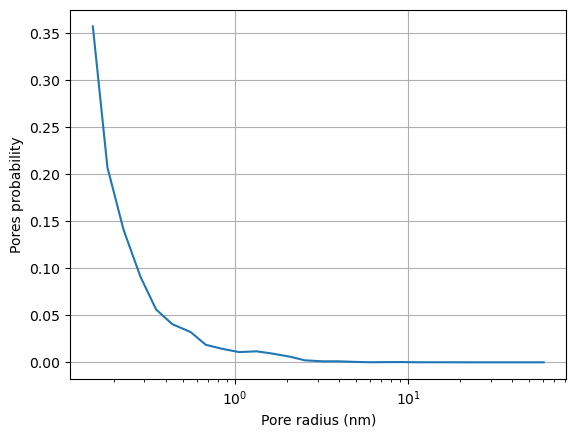

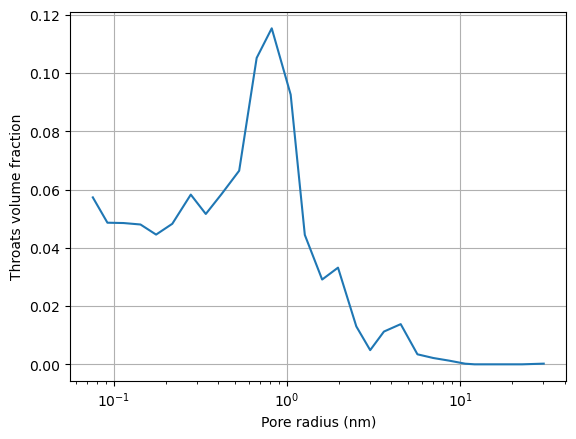

Generated pore count distribution (non-zero bins: 25/29)
Generated throat volume distribution (non-zero bins: 25/29)


<Figure size 640x480 with 0 Axes>

In [13]:
# Compute statistics on the generated network.
# Pores are binned on the pore-scale edges (throat_radii * PRTRR) in COUNT mode so that the
# result is directly comparable to the predicted count distribution pdist (cell 15).
# Throats stay on the experimental throat edges in volume mode (comparable to MIP data).
rbins = throat_radii  # use the same bins as experimental data

pore_bins, pore_dist = stats(
    pn, bins=pore_radii_bins, mode='count', elements='pores', xscale='log', show=True
)
throat_bins, throat_dist = stats(
    pn, bins=rbins, mode='vol', elements='throats', xscale='log', show=True
)

# Normalize (already normalized by stats(), but keep the guard for empty networks)
pore_dist_norm = pore_dist / pore_dist.sum() if pore_dist.sum() > 0 else pore_dist
throat_dist_norm = throat_dist / throat_dist.sum() if throat_dist.sum() > 0 else throat_dist

print(f"Generated pore count distribution (non-zero bins: {(pore_dist_norm>0).sum()}/{len(pore_dist_norm)})")
print(f"Generated throat volume distribution (non-zero bins: {(throat_dist_norm>0).sum()}/{len(throat_dist_norm)})")

plt.show()

[1.000e+00 2.000e+00 4.000e+00 8.000e+00 1.600e+01 3.200e+01 6.400e+01
 1.280e+02 2.560e+02 5.120e+02 1.024e+03]
[     0      7   7475 195902  30015   8373   4490   2414    745    579]


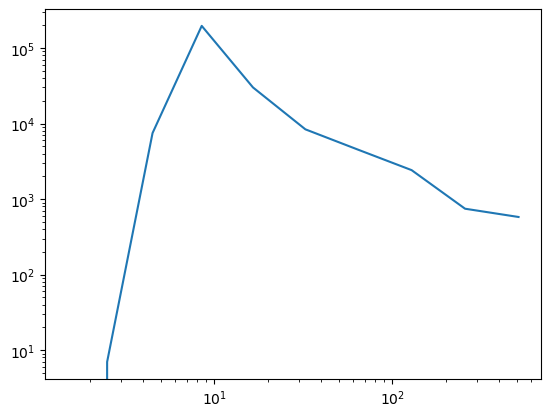

In [14]:
degree, count = pn.connectivity_distribution()
print(degree)
print(count)
plt.plot((degree[:1]+degree[1:])*0.5, count)
plt.xscale("log")
plt.yscale("log")
plt.show()

### Plot comparison


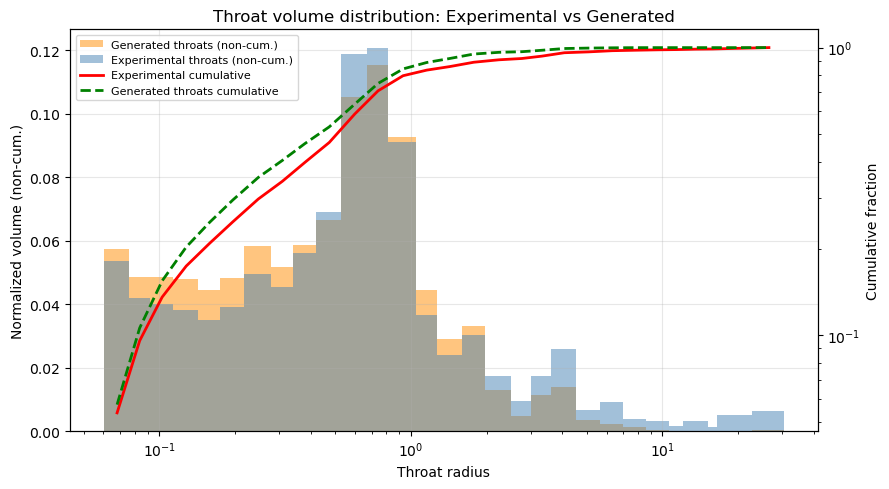

In [15]:
fig, ax1 = plt.subplots(figsize=(9, 5))

# --- Throat distribution comparison (experimental vs generated) ---
bars3 = ax1.bar(midradii, throat_dist_norm, width=deltaR, alpha=0.5,
                label='Generated throats (non-cum.)', color='darkorange')
bars4 = ax1.bar(midradii, volumes, width=deltaR, alpha=0.5,
                label='Experimental throats (non-cum.)', color='steelblue')
ax2_cum = ax1.twinx()
line3, = ax2_cum.plot(midradii, np.cumsum(volumes), 'r-', lw=2,
                      label='Experimental cumulative')
line4, = ax2_cum.plot(midradii, np.cumsum(throat_dist_norm), 'g--', lw=2,
                      label='Generated throats cumulative')
ax1.set_xlabel('Throat radius')
ax1.set_ylabel('Normalized volume (non-cum.)')
ax2_cum.set_ylabel('Cumulative fraction')
ax1.set_title('Throat volume distribution: Experimental vs Generated')
ax1.set_xscale('log')
ax2_cum.set_yscale('log')
ax1.grid(True, alpha=0.3)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2_cum.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

### Pore distribution: predicted vs generated

The target `pdist` is a **count** distribution (one probability per bin, summing to 1 —
see the HDR thesis derivation). Since every drawn pore is placed with its exact radius,
the count histogram of the generated pores must match `pdist` up to Monte-Carlo noise.
Both curves are binned on the pore bins (`throat_radii * PRTRR`).


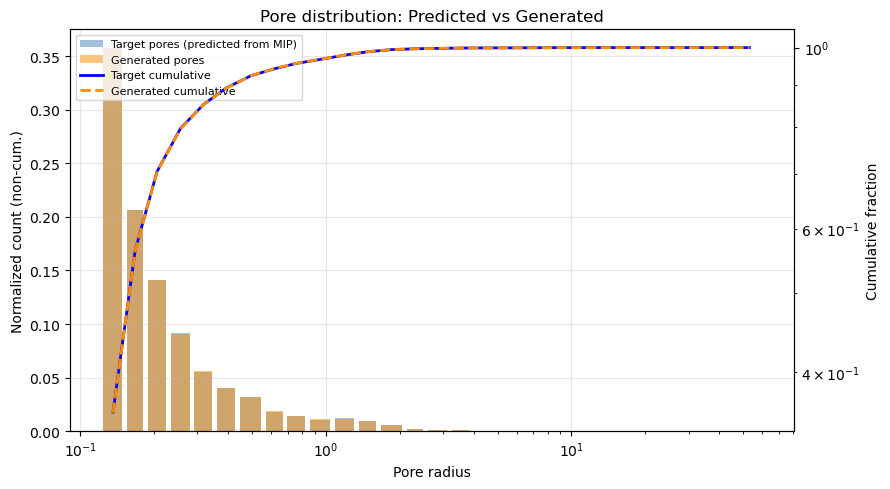

In [16]:
# Pore distribution comparison: predicted target vs generated network (count distributions).
pore_mids = 0.5 * (pore_radii_bins[:-1] + pore_radii_bins[1:])
pore_widths = np.diff(pore_radii_bins) * 0.8

p_counts, _ = np.histogram(
    [pn.graph.nodes[n]["radius"] for n in pn.graph],
    bins=pore_radii_bins,
)
p_counts = p_counts / p_counts.sum()

fig, ax1 = plt.subplots(figsize=(9, 5))

bars1 = ax1.bar(pore_mids, pdist, width=pore_widths, alpha=0.5,
                label='Target pores (predicted from MIP)', color='steelblue')
bars2 = ax1.bar(pore_mids, p_counts, width=pore_widths, alpha=0.5,
                label='Generated pores', color='darkorange')
ax2_pcum = ax1.twinx()
line1, = ax2_pcum.plot(pore_mids, np.cumsum(pdist), 'b-', lw=2,
                       label='Target cumulative')
line2, = ax2_pcum.plot(pore_mids, np.cumsum(p_counts), color='darkorange', ls='--', lw=2,
                       label='Generated cumulative')
ax1.set_xlabel('Pore radius')
ax1.set_ylabel('Normalized count (non-cum.)')
ax2_pcum.set_ylabel('Cumulative fraction')
ax1.set_title('Pore distribution: Predicted vs Generated')
ax1.set_xscale('log')
ax2_pcum.set_yscale('log')
ax1.grid(True, alpha=0.3)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2_pcum.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


## 7. Mercury Intrusion Simulation




We run a mercury intrusion simulation on the generated network and compare
the intrusion curve against the experimental data.

Note: experimental diameters are converted to radii (diameter / 2) for comparison.



In [17]:
# Run mercury intrusion on the generated network
print("Running mercury intrusion simulation...")
Dlist, vint = mercury_intrusion(
    pn,
    faces=("x-", "x+", "y-", "y+", "z-", "z+"),
    D_ratio=1.2,
    Dmax=10.0,
    Dmin=0.01,
    verbose=False,
)

print(f"Intrusion steps: {len(Dlist)}")
print(f"Total intruded volume: {sum(vint):.6f}")

# Normalize by total void volume
total_void = pn.pores_volume + pn.throats_volume
print(f"Total void volume: {total_void:.6f}")
print(f"Intrusion fraction: {sum(vint) / total_void:.4f}")


Running mercury intrusion simulation...


Filling pores with entrance diameter >= 1.00e+01.
Filling pores with entrance diameter >= 8.33e+00.
-Iteration 1    , Volume: 9.00e+02, pores filled: 2    , throats filled 0     
Filling pores with entrance diameter >= 6.94e+00.
-Iteration 1    , Volume: 7.42e+02, pores filled: 3    , throats filled 0     
Filling pores with entrance diameter >= 5.79e+00.
-Iteration 1    , Volume: 1.38e+03, pores filled: 11   , throats filled 0     
Filling pores with entrance diameter >= 4.82e+00.
-Iteration 1    , Volume: 1.01e+03, pores filled: 15   , throats filled 0     
Filling pores with entrance diameter >= 4.02e+00.
-Iteration 1    , Volume: 2.54e+06, pores filled: 258  , throats filled 307   
Filling pores with entrance diameter >= 3.35e+00.


-Iteration 1    , Volume: 1.98e+06, pores filled: 346  , throats filled 488   
Filling pores with entrance diameter >= 2.79e+00.


-Iteration 1    , Volume: 1.26e+05, pores filled: 395  , throats filled 635   
Filling pores with entrance diameter >= 2.33e+00.


-Iteration 1    , Volume: 1.09e+05, pores filled: 540  , throats filled 1190  
Filling pores with entrance diameter >= 1.94e+00.


-Iteration 1    , Volume: 1.10e+05, pores filled: 837  , throats filled 2789  
Filling pores with entrance diameter >= 1.62e+00.


... (24 outputs left out)

Filling pores with entrance diameter >= 1.69e-02.


Filling pores with entrance diameter >= 1.41e-02.


Filling pores with entrance diameter >= 1.18e-02.


Intrusion steps: 38
Total intruded volume: 6195026.794649
Total void volume: 6195026.794649
Intrusion fraction: 1.0000


### Plot experimental vs simulated intrusion curves



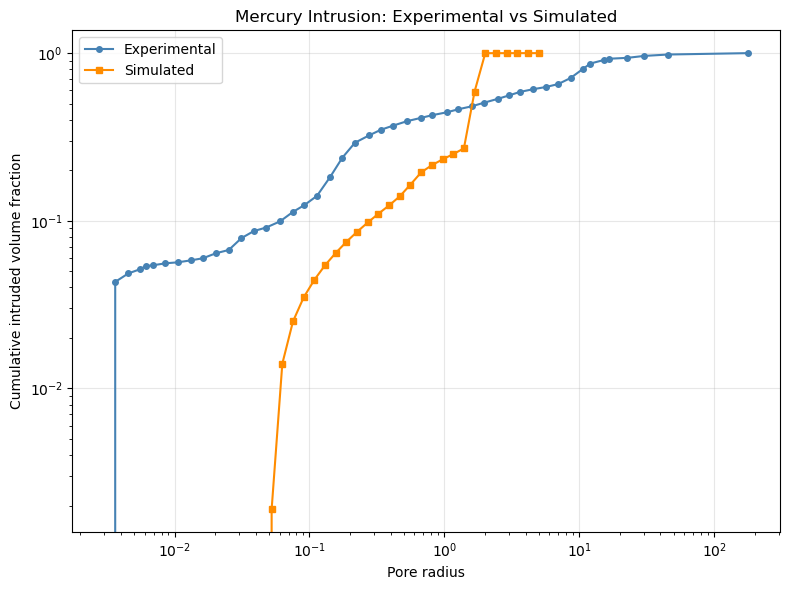

In [18]:
# Experimental intrusion: volume vs diameter (convert diameter -> radius)
# Use the cumulative volume from the original data (before thresholding)
exp_radii = diameters / 2.0
exp_cum_vol = volumes_cum / volumes_cum.max() if volumes_cum.max() > 0 else volumes_cum

# Simulated intrusion: Dlist contains diameters, convert to radius
sim_radii = np.array(Dlist[::-1]) / 2.0  # reverse order (smallest first)
sim_cum_vol = np.cumsum(np.array(vint[::-1])) / total_void

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(exp_radii, exp_cum_vol[::-1], 'o-', label='Experimental', color='steelblue', markersize=4)
ax.plot(sim_radii, sim_cum_vol, 's-', label='Simulated', color='darkorange', markersize=4)

ax.set_xlabel('Pore radius')
ax.set_ylabel('Cumulative intruded volume fraction')
ax.set_title('Mercury Intrusion: Experimental vs Simulated')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
ax.set_yscale('log')

plt.tight_layout()
plt.show()


## 8. 3D Visualization




We visualize the generated network using the fast `Fast3DViewer` (suitable for
large networks) and save a JPEG image of the 3D view.



In [19]:
from pnm.Visualization import Fast3DViewer, vtk_viewer

# Visualize and save image
img_filename = NETWORKS_DIR / f"view-{selected_file[:-4]}-NP{npores}.jpg"

print("Creating 3D visualization...")
vtk_viewer(
    pn,
    save=True,
    render=False,       # False: offscreen rendering only (reproducible, no window).
                       # Set True to open an interactive VTK window (blocks until closed).
    camera=(20, 30),
    cmap='viridis',
    filename=str(img_filename),
    resolution=8,
    attr='radius',
)
print(f"3D image saved to: {img_filename}")

# Also create an interactive viewer (commented out - uncomment to use)
# viewer = Fast3DViewer(pn)
# viewer.render(resolution=8)
# viewer.interact(azimuth=20, elevation=30)

Creating 3D visualization...


Creating pore glyph actor (resolution=8)


3D image saved to: /home/jlux/Nextcloud/Codes/python3/pnm/examples/networks/view-GM1-NP250000.jpg


## Summary




This notebook demonstrated the complete workflow:

1. ✅ Read all experimental MIP data from CSV files and plot intrusion curves
2. ✅ Select one file and prepare the experimental throat distribution
3. ✅ Predict the pore distribution from the throat distribution (corrective factor `e`, PRTRR)
4. ✅ Define model parameters (npores, e, PRTRR, sratio, minc, maxc)
5. ✅ Generate a random pore network using the fast kdtree packing
6. ✅ Compare experimental vs generated pore and throat distributions
7. ✅ Run mercury intrusion simulation and compare intrusion curves
8. ✅ Visualize the network in 3D and save an image

The generated network has been saved to `examples/networks/`.

